A shuttling model of two sites, with two valleys per site, can be written as:
$$
\hat{H} = \left(\begin{matrix}
    \varepsilon/2 + |\Delta_L| & 0 & t_{ee} & t_{eg} \\
    0 & \varepsilon/2-|\Delta_L| & t_{ge} & t_{gg} \\
    t_{ee}^* & t_{ge}^* & -(\varepsilon/2) + |\Delta_R| & 0 \\
    t_{eg}^* & t_{gg}^* & 0 & -(\varepsilon/2) - |\Delta_R|
\end{matrix}\right),
$$
where $\varepsilon$ is the driving parameter, $\Delta_{L,R}$ are the intervalley couplings, and the tunneling rates read
$$
\begin{align}
    t_{ee}&=t_{gg}^*=\frac{t_c}{2}\left(1+e^{i(\phi_L-\phi_R)}\right),\\
    t_{eg}&=-t_{ge}^*=\frac{t_c}{2}\left(e^{i\phi_L}-e^{i\phi_R}\right).
\end{align}
$$

This notebook reproduces Fig. 11, with $\phi_L = 0$, $\phi_R = 0.8\pi$, $|\Delta_L|/t_c = 1$, and $|\Delta_R|/t_c=2$. Energies are given in units of $t_c$, and times in units of $\hbar/t_c$. We obtain the band structure of this system, and the pulses for an adiabatic transfer following the first excited state, including all energy levels in the sum of the hypergeometric tensor. The initial and target states are the first excited eigenstates of the Hamiltonian at $\varepsilon(t=0)=-10\,t_c$ and $\varepsilon(t=t_\mathrm{f})=10\,t_c$, respectively, i.e., the electron is moved from the left to the right dot in the excited valley state, $|L, v_L^+\rangle\mapsto|R, v_R^+\rangle$.

We compare the results for a coherent evolution with those obtained with a Lindblad master equation $\dot{\rho}=-i[\hat{H},\rho]/\hbar+\mathcal{D}[\rho]$, with the dissipator $\mathcal{D}[\rho]=\gamma\sum_i(\lambda_i\rho\lambda_i-\rho\lambda_i^2/2-\lambda_i^2\rho/2)$, where $\lambda_i$ are the three diagonal generalized Gell-Mann matrices (normalized as $\mathrm{Tr}[\lambda_i\lambda_j]=2\delta_{ij}$). This dissipator equals $\mathcal{D}[\rho]=2\gamma(\text{diag}(\rho)-\rho)$, i.e., all coherences decay with the rate $1/T_2=2\gamma$. Here, $\gamma=0.01\,t_c/\hbar$, i.e., $T_2=50\,\hbar/t_c$.

The red crosses denote the coordinates $(\alpha,\beta)$ with the minimum infidelity. The FAQUAD $(4,2)$ and the geometric fast-QUAD $(2,2)$ fidelities are printed for comparison.

In [1]:
import colorstamps
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap
from parameterrun import parameterrun

from HQUAD_lib.hamiltonians import two_valleys_system
from HQUAD_lib.physics_utils import fidelity_shuttling
from HQUAD_lib.QUAD_utils import compute_x_quad

# Band structure

In [2]:
tc = 1
phiL = 0 * np.pi
phiR = 0.8 * np.pi
DeltaL = 1
DeltaR = 2

eps_s = np.linspace(-10, 10, 2**18 + 1)  # 2 ** 20 + 1 points in the manuscript

partial_hamiltonian = np.array(
    [two_valleys_system(1, 0, 0, 0, 0, 0) for _ in range(len(eps_s))]
)

hypermatrix = np.array(
    [two_valleys_system(eps, tc, phiL, phiR, DeltaL, DeltaR) for eps in eps_s]
)
eigvalues, eigmodes = np.linalg.eigh(hypermatrix)

# Pulses

In [3]:
alphas = np.linspace(
    -5, 5, 21
)  # Increase to enhance resolution (101 values in the manuscript)
betas = alphas

limit_sup = 1e8
n_s = 2**12 + 1  # Number of time steps for the pulse

s, eps_sol = np.asarray(
    parameterrun(
        compute_x_quad,
        [["alpha"], ["beta"]],
        [[alphas], [betas]],
        energies=eigvalues,
        states=eigmodes,
        x_vec=eps_s,
        partial_hamiltonian=partial_hamiltonian,
        adiabatic_state=1,
        limit_sup=limit_sup,
        n_s=n_s,
    )
)

s = s[0, 0]  # The time grid is the same for all the pulses
eps_sol = eps_sol.reshape((len(alphas), len(betas), len(s)))

compute_x_quad: [['alpha'], ['beta']]:   0%|          | 0/441 [00:00<?, ?it/s]

In [4]:
def compute_fidelity(pulse: np.ndarray, tf: float, gamma: float = 0) -> float:
    # Pulses that do not reach the final value of the detuning are discarded
    if pulse[-1] > eps_s[-1] + 0.5:
        return np.nan

    return fidelity_shuttling(
        pulse, tf, tc, phiL, phiR, DeltaL, DeltaR, gamma=gamma, adiabatic_state=1
    )

# Coherent evolution

In [5]:
n_tf = 40  # Increase to get better results (200 values in the manuscript)
tf_list = np.linspace(0.1, 100, n_tf)

fidelities_pure = np.asarray(
    parameterrun(
        compute_fidelity,
        [["pulse"], ["tf"]],
        [[eps_sol.reshape((-1, len(s)))], [tf_list]],
    )
)
fidelities_pure = fidelities_pure.reshape((len(alphas), len(betas), n_tf))

compute_fidelity: [['pulse'], ['tf']]:   0%|          | 0/17640 [00:00<?, ?it/s]

# Dephasing

In [6]:
gamma = 0.01
print(f"T_2 = {1 / (2 * gamma):.0f} hbar / t_c")

fidelities_dephasing = np.asarray(
    parameterrun(
        compute_fidelity,
        [["pulse"], ["tf"]],
        [[eps_sol.reshape((-1, len(s)))], [tf_list]],
        gamma=gamma,
    )
)
fidelities_dephasing = fidelities_dephasing.reshape((len(alphas), len(betas), n_tf))

T_2 = 50 hbar / t_c


compute_fidelity: [['pulse'], ['tf']]:   0%|          | 0/17640 [00:00<?, ?it/s]

# Plots

In [7]:
cmap_fidelity = ListedColormap(mpl.colormaps["viridis_r"](np.linspace(0, 0.9, 256)))
cmap_fidelity.set_bad("white")
cmap_tf = mpl.colormaps["inferno_r"].copy()
cmap_tf.set_bad("white")


def plot_fidelity(
    axs: np.ndarray,
    fidelities: np.ndarray,
    tf_list: np.ndarray,
    alphas: np.ndarray,
    betas: np.ndarray,
    clabel: bool = True,
) -> None:
    fidelities = np.nan_to_num(fidelities, nan=0)  # Discarded pulses are shown in white

    max_fidelity = np.max(fidelities, axis=2)
    tf_tilde = tf_list[np.argmax(fidelities, axis=2)]

    data_fidelity = np.log10(1 - max_fidelity)
    data_fidelity[max_fidelity == 0] = np.nan
    data_tf = tf_tilde
    data_tf[max_fidelity == 0] = np.nan

    im0 = axs[0].contourf(alphas, betas, data_fidelity.T, levels=15, cmap=cmap_fidelity)
    im1 = axs[1].contourf(alphas, betas, data_tf.T, levels=15, cmap=cmap_tf)

    for im in [im0, im1]:
        im.set_edgecolor("face")

    if clabel:
        label0 = r"$\log_{10}(1 - \tilde{\mathcal{F}})$"
        label1 = r"$\tilde{t}_\mathrm{f}\; [\hbar / t_c]$"
    else:
        label0 = None
        label1 = None

    cbar0 = plt.colorbar(im0, ax=axs[0], label=label0, location="top")
    cbar1 = plt.colorbar(im1, ax=axs[1], label=label1, location="top")

    cbar0.ax.set_xticks(cbar0.ax.get_xticks()[::3])
    cbar1.ax.set_xticks(cbar1.ax.get_xticks()[::2])

    for cbar in [cbar0, cbar1]:
        if cbar.solids is not None:
            cbar.solids.set_edgecolor("face")

    for ax in axs:
        ax.set_xlabel(r"$\alpha$")

    axs[0].set_ylabel(r"$\beta$")

Coherent evolution:
    Best: 1 - F = 1.81e-06 at (alpha, beta) = (2.50, 0.50)
    FAQUAD: 1 - F = 6.39e-04
    Geometric: 1 - F = 5.24e-05
Dephasing evolution:
    Best: 1 - F = 1.12e-01 at (alpha, beta) = (3.50, 1.50)
    FAQUAD: 1 - F = 1.49e-01
    Geometric: 1 - F = 1.79e-01


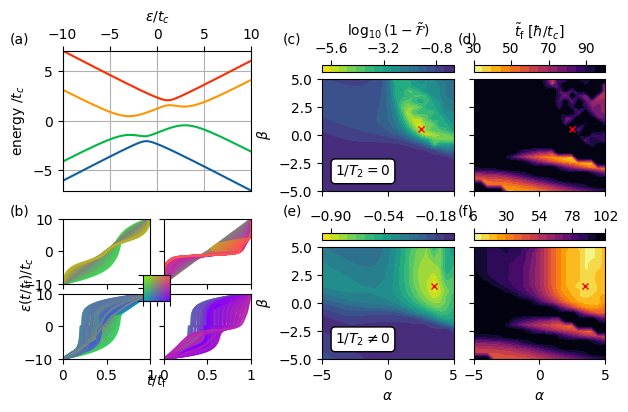

In [8]:
fig = plt.figure(figsize=(7, 4))
gs0 = fig.add_gridspec(1, 2, wspace=0.3, width_ratios=[1, 1.5])

# (a) Band structure
gs00 = gs0[0].subgridspec(2, 1)
axBand = fig.add_subplot(gs00[0])

for eigvalue, color in zip(eigvalues.T, ["#0C5DA5", "#00B945", "#FF9500", "#FF2C00"]):
    axBand.plot(eps_s, eigvalue, color=color)
axBand.grid()
axBand.set_xlim(min(eps_s), max(eps_s))
axBand.set_ylim(np.min(eigvalues), np.max(eigvalues))

axBand.set_xlabel(r"$\varepsilon / t_c$")
axBand.set_ylabel(r"energy $/t_c$")
axBand.xaxis.tick_top()
axBand.xaxis.set_label_position("top")

# (c-d) Coherent evolution and (e-f) dephasing
gsFidelities = gs0[1].subgridspec(2, 2, wspace=0.15)
axsFidelity = np.array(
    [[fig.add_subplot(gsFidelities[i, j]) for j in range(2)] for i in range(2)]
)

plot_fidelity(axsFidelity[0], fidelities_pure, tf_list, alphas, betas)
for ax in axsFidelity[0]:
    ax.set_xticklabels([])
    ax.set_xlabel("")

plot_fidelity(
    axsFidelity[1], fidelities_dephasing, tf_list, alphas, betas, clabel=False
)

for ax in axsFidelity[:, 1]:
    ax.set_yticklabels([])

# Best coordinates, FAQUAD and geometric fast-QUAD
index_FAQUAD = (np.argmin(np.abs(alphas - 4)), np.argmin(np.abs(betas - 2)))
index_geometric = (np.argmin(np.abs(alphas - 2)), np.argmin(np.abs(betas - 2)))

for row, (fidelities, title) in enumerate(
    zip([fidelities_pure, fidelities_dephasing], ["Coherent", "Dephasing"])
):
    max_fidelity = np.max(np.nan_to_num(fidelities, nan=0), axis=2)
    best_indices = np.where(max_fidelity == np.max(max_fidelity))

    for ax in axsFidelity[row]:
        ax.plot(alphas[best_indices[0]], betas[best_indices[1]], "rx", markersize=5)

    print(f"{title} evolution:")
    print(
        f"    Best: 1 - F = {1 - np.max(max_fidelity):.2e} at (alpha, beta) = "
        f"({alphas[best_indices[0]][0]:.2f}, {betas[best_indices[1]][0]:.2f})"
    )
    print(f"    FAQUAD: 1 - F = {1 - max_fidelity[index_FAQUAD]:.2e}")
    print(f"    Geometric: 1 - F = {1 - max_fidelity[index_geometric]:.2e}")

for ax, text in zip(axsFidelity[:, 0], [r"$1 / T_2 = 0$", r"$1 / T_2 \neq 0$"]):
    ax.text(
        0.1,
        0.1,
        text,
        ha="left",
        transform=ax.transAxes,
        va="bottom",
        bbox={"boxstyle": "round", "ec": "k", "fc": "w", "alpha": 1},
    )

# (b) Pulses, in a different panel for each quadrant of the (alpha, beta) plane
gsPulses = gs00[1].subgridspec(2, 2, wspace=0.15, hspace=0.15)
axsPulses = np.array(
    [[fig.add_subplot(gsPulses[i, j]) for j in range(2)] for i in range(2)]
)

betas_grid, alphas_grid = np.meshgrid(betas, alphas)
rgb, stamp = colorstamps.apply_stamp(betas_grid, alphas_grid, "teuling0f")

for i in range(len(alphas)):
    for j in range(len(betas)):
        column = 1 if alphas[i] >= 0 else 0
        row = 0 if betas[j] >= 0 else 1
        axsPulses[row, column].plot(s, eps_sol[i, j], c=rgb[i, j])

for ax in axsPulses.flatten():
    ax.set_xlim(0, 1)
    ax.set_ylim(-10, 10)

for ax in axsPulses[-1]:
    ax.set_xticks([0, 0.5, 1])
    ax.set_xticklabels(["0", "0.5", "1"])

axsPulses[1, 0].text(
    1.07, -0.4, r"$t / t_\mathrm{f}$", ha="center", transform=axsPulses[1, 0].transAxes
)
axsPulses[1, 0].text(
    -0.5,
    1.15,
    r"$\varepsilon(t / t_\mathrm{f}) /t_c$",
    va="center",
    rotation="vertical",
    transform=axsPulses[1, 0].transAxes,
)

for ax in axsPulses[:, 1]:
    ax.set_yticklabels([])

for ax in axsPulses[0]:
    ax.set_xticklabels([])

overlaid_ax = stamp.overlay_ax(
    axsPulses[1, 0], width=0.3, lower_left_corner=[0.88, 0.92]
)
overlaid_ax.set_xticklabels([])
overlaid_ax.set_yticklabels([])

# Panel labels
letters = ["a", "c", "d", "b", "e", "f"]
xs = [0.05, 0.44, 0.69]
ys = [0.9, 0.47]
for row in range(2):
    for column in range(3):
        fig.text(xs[column], ys[row], f"({letters[column + 3 * row]})")